  ## importing libraries and loading the cleaned crop-yield data

In [1]:
## importing libraries and loading the cleaned crop-yield data
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FILE_DIR = Path.cwd() / "Data_Collection"
DATA_PATH = FILE_DIR / "country_crop_data.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Run 01_Data_Preprocessing.ipynb first "
        "and make sure this notebook is in the same project folder."
    )

country_crop_data = pd.read_csv(DATA_PATH)
required_cols = {"Area", "Item", "Year", "Yield_kg_ha"}
missing_cols = required_cols - set(country_crop_data.columns)
if missing_cols:
    raise ValueError(f"Cleaned dataset is missing required columns: {sorted(missing_cols)}")

country_crop_data["Year"] = pd.to_numeric(country_crop_data["Year"], errors="raise").astype(int)
country_crop_data["Yield_kg_ha"] = pd.to_numeric(country_crop_data["Yield_kg_ha"], errors="coerce")
country_crop_data = country_crop_data.dropna(subset=["Area", "Item", "Year", "Yield_kg_ha"]).copy()
crop_order = ["Maize (corn)", "Rice", "Wheat"]
country_crop_data = country_crop_data[country_crop_data["Item"].isin(crop_order)].copy()

if country_crop_data.empty:
    raise ValueError("No records found for Maize (corn), Rice, or Wheat.")

print("Dataset shape:", country_crop_data.shape)
print("Areas:", country_crop_data["Area"].nunique())
print("Years:", country_crop_data["Year"].min(), "to", country_crop_data["Year"].max())
display(country_crop_data.head())

Dataset shape: (24588, 8)
Areas: 196
Years: 1961 to 2023


,Area Code,Area,Item Code,Item,Element,Unit,Year,Yield_kg_ha
0,1,Armenia,15,Wheat,Yield,kg/ha,1992,2160.0
1,1,Armenia,15,Wheat,Yield,kg/ha,1993,2225.7
2,1,Armenia,15,Wheat,Yield,kg/ha,1994,1784.2
3,1,Armenia,15,Wheat,Yield,kg/ha,1995,2548.0
4,1,Armenia,15,Wheat,Yield,kg/ha,1996,2356.9


  ## Univariate Analysis
 ## Q1 — checking dataset shape, first rows, and data types

In [2]:
  ## Univariate Analysis
## Q1 — checking dataset shape, first rows, and data types
print("Rows and columns:", country_crop_data.shape)
display(country_crop_data.head())
display(country_crop_data.dtypes.to_frame("data_type"))

Rows and columns: (24588, 8)


,Area Code,Area,Item Code,Item,Element,Unit,Year,Yield_kg_ha
0,1,Armenia,15,Wheat,Yield,kg/ha,1992,2160.0
1,1,Armenia,15,Wheat,Yield,kg/ha,1993,2225.7
2,1,Armenia,15,Wheat,Yield,kg/ha,1994,1784.2
3,1,Armenia,15,Wheat,Yield,kg/ha,1995,2548.0
4,1,Armenia,15,Wheat,Yield,kg/ha,1996,2356.9


,data_type
Area Code,int64
Area,object
Item Code,int64
Item,object
Element,object
Unit,object
Year,int64
Yield_kg_ha,float64


 ## Q2 — calculating yield summary statistics

In [3]:
## Q2 — calculating yield summary statistics
display(country_crop_data.groupby("Item")["Yield_kg_ha"].agg(
    observations="count", minimum="min", mean="mean", median="median",
    standard_deviation="std", maximum="max"
).round(2))

,observations,minimum,mean,median,standard_deviation,maximum
Item,,,,,,
Maize (corn),9820,0.1,3186.85,1900.75,3324.53,39405.7
Rice,7488,96.8,3231.33,2808.55,1937.47,11351.1
Wheat,7280,0.0,2566.75,2068.55,1801.38,10667.7


 ## Q3 — counting observations for each crop

,observations
Item,
Maize (corn),9820
Rice,7488
Wheat,7280


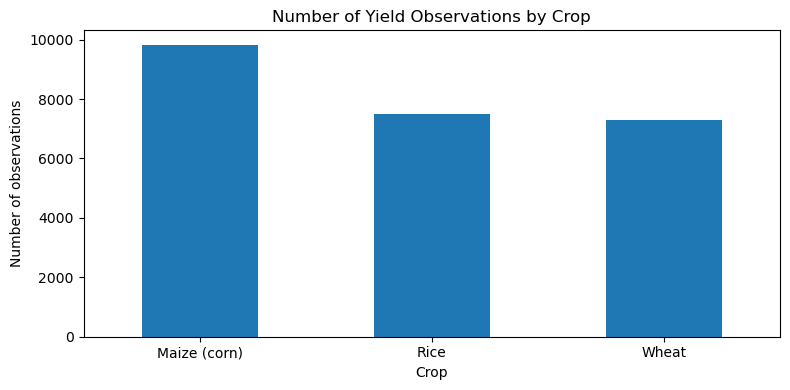

In [4]:
## Q3 — counting observations for each crop
crop_counts = country_crop_data["Item"].value_counts().reindex(crop_order, fill_value=0)
display(crop_counts.rename("observations").to_frame())
ax = crop_counts.plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_title("Number of Yield Observations by Crop")
ax.set_xlabel("Crop")
ax.set_ylabel("Number of observations")
plt.tight_layout()
plt.show()

 ## Q4 — plotting yield distributions for each crop

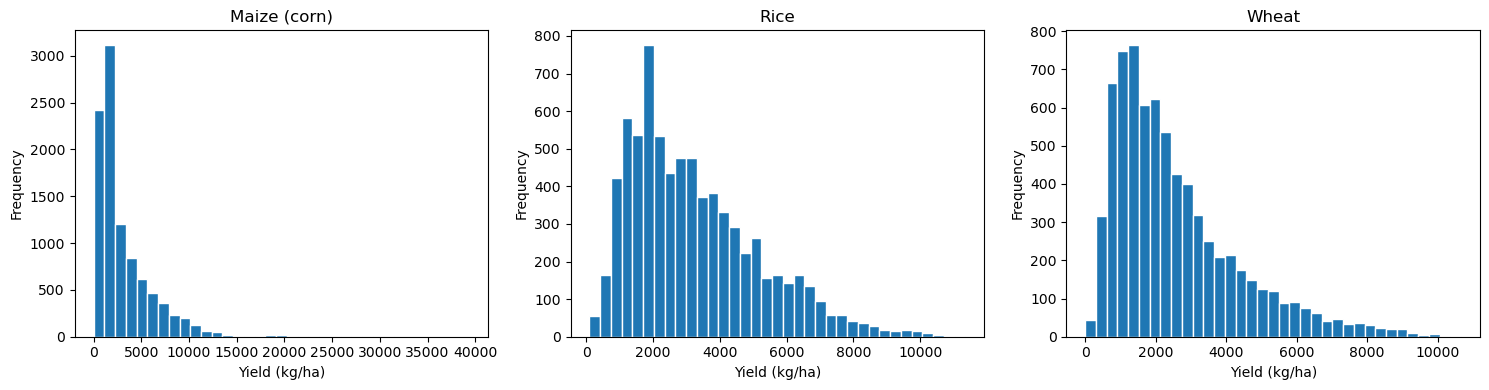

In [5]:
## Q4 — plotting yield distributions for each crop
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, crop in zip(axes, crop_order):
    values = country_crop_data.loc[country_crop_data["Item"] == crop, "Yield_kg_ha"]
    ax.hist(values, bins=35, edgecolor="white")
    ax.set_title(crop)
    ax.set_xlabel("Yield (kg/ha)")
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

 ## Q5 — comparing median yield by crop

In [6]:
## Q5 — comparing median yield by crop
median_by_crop = country_crop_data.groupby("Item")["Yield_kg_ha"].median().reindex(crop_order)
display(median_by_crop.rename("median_yield_kg_ha").to_frame().round(2))
print("Highest median:", median_by_crop.idxmax())
print("Lowest median:", median_by_crop.idxmin())

,median_yield_kg_ha
Item,
Maize (corn),1900.75
Rice,2808.55
Wheat,2068.55


Highest median: Rice
Lowest median: Maize (corn)


 ## Q6 — counting zero and negative yields by crop

In [7]:
## Q6 — counting zero and negative yields by crop
yield_quality = country_crop_data.groupby("Item").agg(
    zero_yields=("Yield_kg_ha", lambda s: int((s == 0).sum())),
    negative_yields=("Yield_kg_ha", lambda s: int((s < 0).sum())),
    observations=("Yield_kg_ha", "size")
).reindex(crop_order)
display(yield_quality)
print("Investigate zero/negative values against the source before deciding how to handle them.")

,zero_yields,negative_yields,observations
Item,,,
Maize (corn),0,0,9820
Rice,0,0,7488
Wheat,15,0,7280


Investigate zero/negative values against the source before deciding how to handle them.


 ## Q7 — listing the ten highest recorded yields

In [8]:
## Q7 — listing the ten highest recorded yields
top_10_yields = country_crop_data.nlargest(10, "Yield_kg_ha")[
    ["Area", "Item", "Year", "Yield_kg_ha"]
]
display(top_10_yields.reset_index(drop=True))
print("These are review candidates, not automatically invalid records.")

,Area,Item,Year,Yield_kg_ha
0,Oman,Maize (corn),2022,39405.7
1,United Arab Emirates,Maize (corn),2013,36761.9
2,United Arab Emirates,Maize (corn),2015,35291.3
3,Israel,Maize (corn),2014,34097.7
4,Israel,Maize (corn),2011,33815.8
5,United Arab Emirates,Maize (corn),2016,33396.5
6,Kuwait,Maize (corn),2013,31147.8
7,United Arab Emirates,Maize (corn),2017,30801.8
8,Kuwait,Maize (corn),2014,30753.2
9,Oman,Maize (corn),2021,30691.0


These are review candidates, not automatically invalid records.


 ## Q8 — checking yearly observation coverage

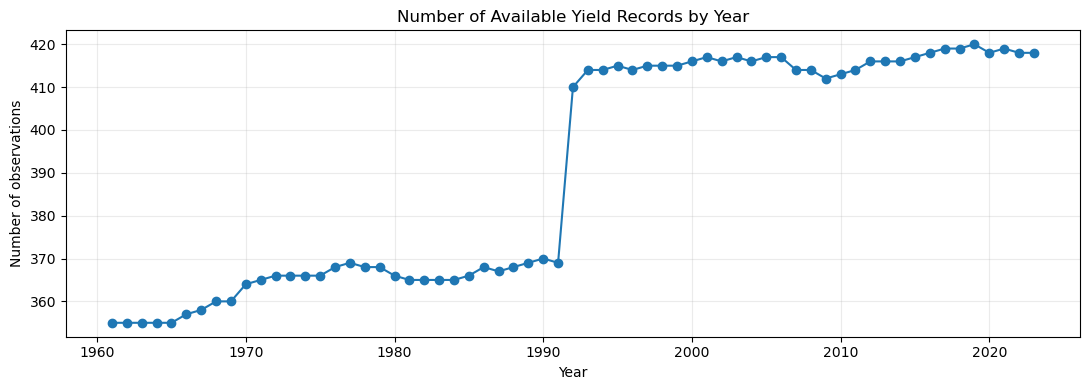

,observations
Year,
2014,416
2015,417
2016,418
2017,419
2018,419
2019,420
2020,418
2021,419
2022,418


In [9]:
## Q8 — checking yearly observation coverage
year_counts = country_crop_data.groupby("Year").size().sort_index()
ax = year_counts.plot(figsize=(11, 4), marker="o")
ax.set_title("Number of Available Yield Records by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of observations")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
display(year_counts.rename("observations").to_frame().tail(10))

 ## Q9 — calculating yield quartiles by crop

In [10]:
## Q9 — calculating yield quartiles by crop
quartiles = country_crop_data.groupby("Item")["Yield_kg_ha"].quantile([0.25, 0.50, 0.75]).unstack()
quartiles.columns = ["25th_percentile", "50th_percentile_median", "75th_percentile"]
display(quartiles.reindex(crop_order).round(2))

,25th_percentile,50th_percentile_median,75th_percentile
Item,,,
Maize (corn),1136.57,1900.75,4175.47
Rice,1754.18,2808.55,4354.52
Wheat,1235.52,2068.55,3380.88


 ## Q10 — checking yield skewness and boxplots

,yield_skewness
Item,
Maize (corn),3.074
Rice,0.946
Wheat,1.342


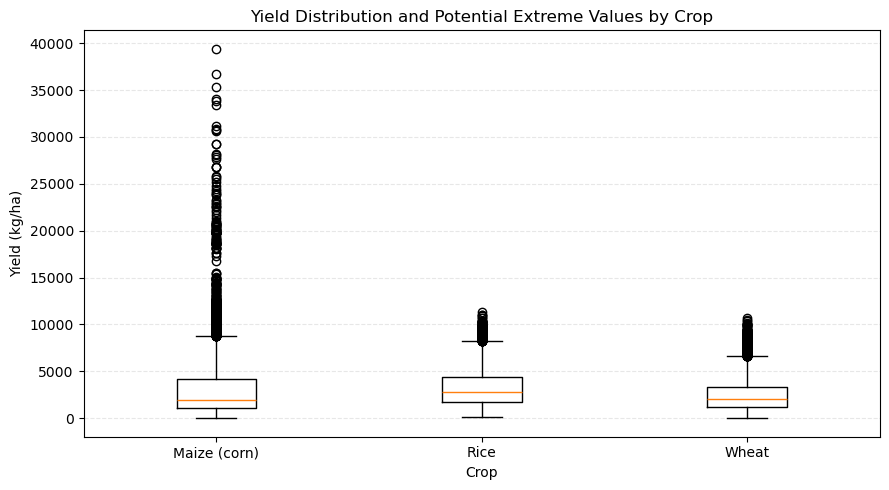

Interpretation: Positive skewness indicates a longer right tail, often caused by some unusually high yields. Negative skewness indicates a longer left tail. Values near zero suggest less skewness.
Boxplot points outside the whiskers are potential outliers, not automatically incorrect observations. Investigate them before deciding whether to retain or remove them.


In [11]:

## Q10 — checking yield skewness and boxplots

# Calculate yield skewness for each crop
skewness = (country_crop_data.groupby("Item")["Yield_kg_ha"].skew().reindex(crop_order))

display(skewness.rename("yield_skewness").to_frame().round(3))

# Prepare yield distributions for the boxplot
box_data = [country_crop_data.loc[country_crop_data["Item"] == crop,"Yield_kg_ha"].dropna()
    for crop in crop_order]

# Create the boxplot
fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(box_data,tick_labels=crop_order,showfliers=True)

ax.set_title("Yield Distribution and Potential Extreme Values by Crop")
ax.set_xlabel("Crop")
ax.set_ylabel("Yield (kg/ha)")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# Interpret the skewness
print(
    "Interpretation: Positive skewness indicates a longer right tail, "
    "often caused by some unusually high yields. Negative skewness "
    "indicates a longer left tail. Values near zero suggest less skewness.")

print(
    "Boxplot points outside the whiskers are potential outliers, "
    "not automatically incorrect observations. Investigate them before "
    "deciding whether to retain or remove them.")


  ## Bivariate Analysis
 ## Q11 — comparing yield distributions across crops

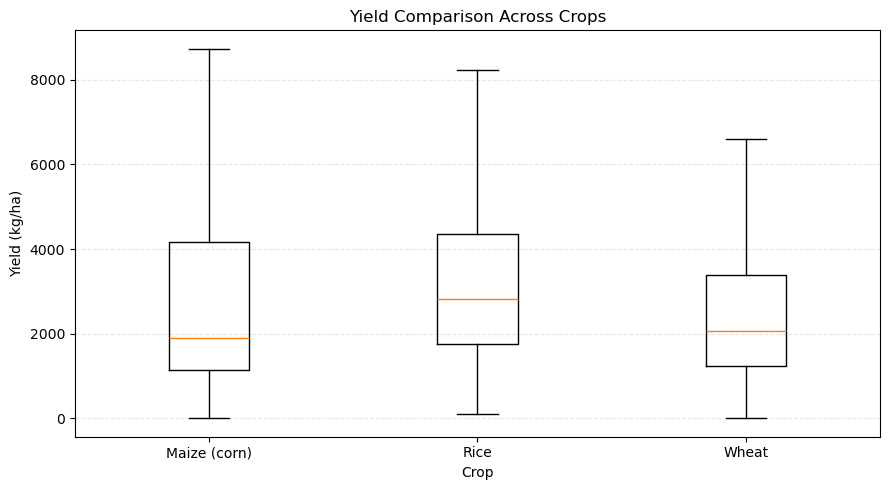

,count,median,mean
Item,,,
Maize (corn),9820,1900.75,3186.85
Rice,7488,2808.55,3231.33
Wheat,7280,2068.55,2566.75


In [12]:

# ## Bivariate Analysis
# ## Q11 — comparing yield distributions across crops

# Prepare yield data for each crop
box_data = [country_crop_data.loc[country_crop_data["Item"] == crop,"Yield_kg_ha"].dropna()
    for crop in crop_order]

# Create a boxplot to compare crop yields
fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(box_data,tick_labels=crop_order,showfliers=False)

ax.set_title("Yield Comparison Across Crops")
ax.set_xlabel("Crop")
ax.set_ylabel("Yield (kg/ha)")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# Compare summary statistics across crops
crop_yield_summary = (country_crop_data.groupby("Item")["Yield_kg_ha"].agg(["count", "median", "mean"]).reindex(crop_order).round(2))

display(crop_yield_summary)


 ## Q12 — plotting annual median yield trends by crop

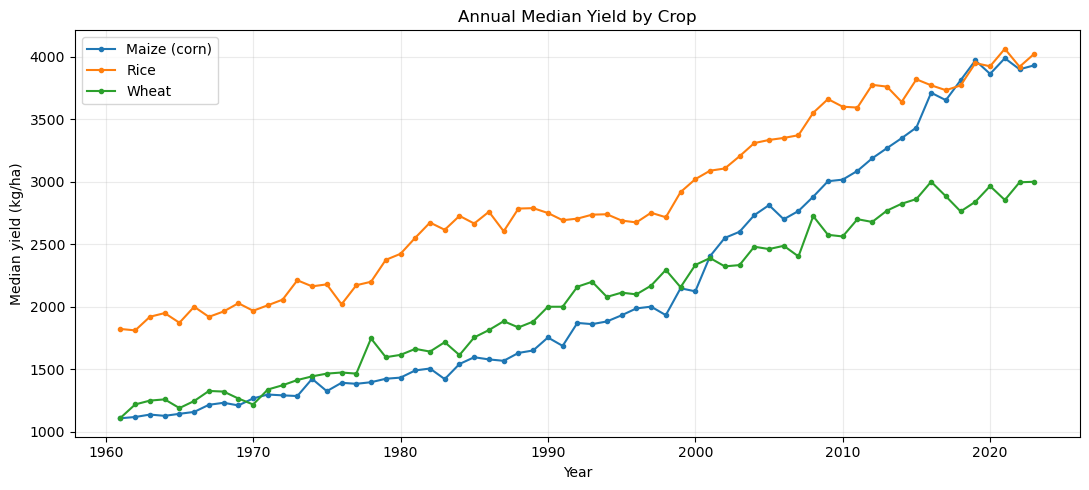

The set of areas reporting data can change by year; interpret trends with that limitation in mind.


In [13]:
## Q12 — plotting annual median yield trends by crop
yearly = country_crop_data.groupby(["Year", "Item"])["Yield_kg_ha"].median().reset_index()
fig, ax = plt.subplots(figsize=(11, 5))
for crop in crop_order:
    g = yearly[yearly["Item"] == crop]
    ax.plot(g["Year"], g["Yield_kg_ha"], marker=".", label=crop)
ax.set_title("Annual Median Yield by Crop")
ax.set_xlabel("Year")
ax.set_ylabel("Median yield (kg/ha)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print("The set of areas reporting data can change by year; interpret trends with that limitation in mind.")

 ## Q13 — finding areas with highest average yield per crop

In [14]:
## Q13 — finding areas with highest average yield per crop
area_crop_summary = country_crop_data.groupby(["Item", "Area"])["Yield_kg_ha"].agg(
    observations="count", mean_yield="mean"
).reset_index()
for crop in crop_order:
    print(f"Top areas for {crop} (at least 10 observations):")
    display(area_crop_summary[
        (area_crop_summary["Item"] == crop) & (area_crop_summary["observations"] >= 10)
    ].nlargest(10, "mean_yield").round(2))

Top areas for Maize (corn) (at least 10 observations):


,Item,Area,observations,mean_yield
169,Maize (corn),United Arab Emirates,34,22456.75
89,Maize (corn),Kuwait,52,14255.96
130,Maize (corn),Qatar,35,13582.48
82,Maize (corn),Israel,63,12990.30
15,Maize (corn),Belgium,24,10588.10
138,Maize (corn),Saint Vincent and the Grenadines,63,9559.14
120,Maize (corn),Oman,33,9304.03
114,Maize (corn),New Zealand,63,9106.26
9,Maize (corn),Austria,63,8080.22
157,Maize (corn),Switzerland,63,7964.84


Top areas for Rice (at least 10 observations):


,Item,Area,observations,mean_yield
187,Rice,Australia,63,7871.58
188,Rice,Australia and New Zealand,63,7871.58
219,Rice,Egypt,63,7368.32
289,Rice,Spain,63,6654.70
266,Rice,Northern America,63,6467.02
306,Rice,United States of America,63,6467.02
230,Rice,Greece,63,6388.83
244,Rice,Japan,63,6156.41
275,Rice,Republic of Korea,63,6011.34
242,Rice,Italy,63,5793.12


Top areas for Wheat (at least 10 observations):


,Item,Area,observations,mean_yield
326,Wheat,Belgium,24,8580.91
397,Wheat,Netherlands (Kingdom of the),63,7164.38
369,Wheat,Ireland,63,7017.28
441,Wheat,United Kingdom of Great Britain and Northern I...,63,6502.88
349,Wheat,Denmark,63,6308.95
361,Wheat,Germany,63,6021.86
383,Wheat,Luxembourg,24,5999.78
359,Wheat,France,63,5760.35
399,Wheat,New Zealand,63,5687.30
327,Wheat,Belgium-Luxembourg,39,5507.65


 ## Q14 — finding areas with lowest average yield per crop

In [15]:
## Q14 — finding areas with lowest average yield per crop
for crop in crop_order:
    print(f"Lowest average yields for {crop} (at least 10 observations):")
    display(area_crop_summary[
        (area_crop_summary["Item"] == crop) & (area_crop_summary["observations"] >= 10)
    ].nsmallest(10, "mean_yield").round(2))

Lowest average yields for Maize (corn) (at least 10 observations):


,Item,Area,observations,mean_yield
27,Maize (corn),Cabo Verde,63,337.21
22,Maize (corn),Botswana,63,356.10
175,Maize (corn),Vanuatu,63,529.61
102,Maize (corn),Mauritania,63,648.15
3,Maize (corn),Angola,63,683.97
107,Maize (corn),Morocco,63,710.43
55,Maize (corn),Eritrea,31,727.68
154,Maize (corn),Sudan (former),51,738.04
31,Maize (corn),Central African Republic,63,760.11
108,Maize (corn),Mozambique,63,765.24


Lowest average yields for Rice (at least 10 observations):


,Item,Area,observations,mean_yield
210,Rice,Comoros,63,682.27
216,Rice,Democratic Republic of the Congo,63,794.58
259,Rice,Mozambique,63,859.03
211,Rice,Congo,63,915.65
312,Rice,Zambia,56,1090.49
185,Rice,Angola,63,1095.62
249,Rice,Liberia,63,1125.23
313,Rice,Zimbabwe,63,1198.93
203,Rice,Chad,63,1228.09
202,Rice,Central African Republic,63,1252.97


Lowest average yields for Wheat (at least 10 observations):


,Item,Area,observations,mean_yield
423,Wheat,Somalia,54,275.09
364,Wheat,Honduras,63,650.18
381,Wheat,Libya,63,652.70
334,Wheat,Burundi,63,719.48
380,Wheat,Lesotho,63,777.11
352,Wheat,Eritrea,31,833.69
433,Wheat,Thailand,38,846.16
417,Wheat,Rwanda,63,892.68
329,Wheat,Bolivia (Plurinational State of),63,913.52
350,Wheat,Ecuador,63,937.14


 ## Q15 — checking relationship between previous-year and current yield

Matched consecutive-year observations: 24120
Maize (corn): correlation = 0.953
Rice: correlation = 0.967
Wheat: correlation = 0.961


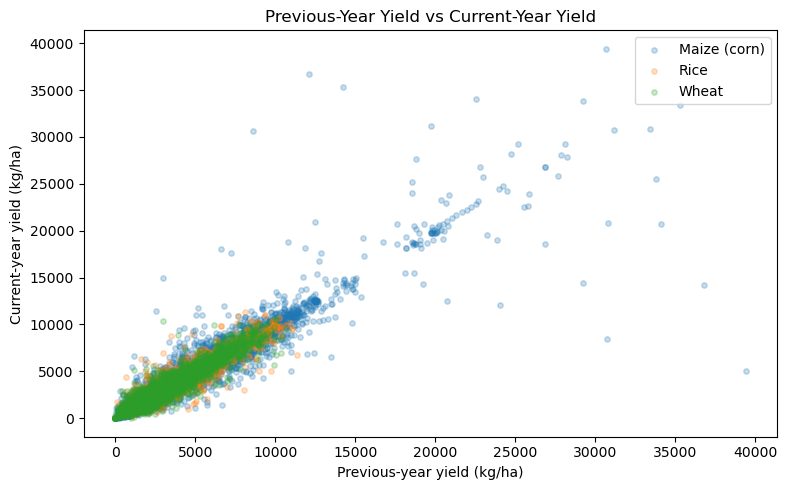

In [16]:
## Q15 — checking relationship between previous-year and current yield
# Match the previous calendar year explicitly; do not treat gaps as consecutive years.
lag_source = country_crop_data[["Area", "Item", "Year", "Yield_kg_ha"]].copy()
previous = lag_source.rename(columns={"Year": "Previous_Year", "Yield_kg_ha": "Yield_lag_1"})
previous["Year"] = previous["Previous_Year"] + 1
lagged = lag_source.merge(previous[["Area", "Item", "Year", "Yield_lag_1"]], on=["Area", "Item", "Year"], how="inner")
print("Matched consecutive-year observations:", len(lagged))
for crop in crop_order:
    g = lagged[lagged["Item"] == crop]
    print(f"{crop}: correlation = {g['Yield_lag_1'].corr(g['Yield_kg_ha']):.3f}" if len(g) > 1 else f"{crop}: not enough records")
fig, ax = plt.subplots(figsize=(8, 5))
for crop in crop_order:
    g = lagged[lagged["Item"] == crop]
    ax.scatter(g["Yield_lag_1"], g["Yield_kg_ha"], alpha=0.25, s=15, label=crop)
ax.set_title("Previous-Year Yield vs Current-Year Yield")
ax.set_xlabel("Previous-year yield (kg/ha)")
ax.set_ylabel("Current-year yield (kg/ha)")
ax.legend()
plt.tight_layout()
plt.show()

 ## Q16 — comparing correlations with two-year and three-year lags

In [17]:
## Q16 — comparing correlations with two-year and three-year lags
lagged_data = country_crop_data[["Area", "Item", "Year", "Yield_kg_ha"]].copy()
for k in [2, 3]:
    prior = lagged_data[["Area", "Item", "Year", "Yield_kg_ha"]].copy()
    prior["Year"] = prior["Year"] + k
    prior = prior.rename(columns={"Yield_kg_ha": f"Yield_lag_{k}"})
    lagged_data = lagged_data.merge(prior, on=["Area", "Item", "Year"], how="left")
rows = []
for crop in crop_order:
    g = lagged_data[lagged_data["Item"] == crop]
    rows.append({
        "Item": crop,
        "lag_1_correlation": g["Yield_kg_ha"].corr(g["Yield_lag_1"]) if "Yield_lag_1" in g else np.nan,
        "lag_2_correlation": g["Yield_kg_ha"].corr(g["Yield_lag_2"]),
        "lag_3_correlation": g["Yield_kg_ha"].corr(g["Yield_lag_3"]),
        "observations_lag_2": int(g[["Yield_kg_ha", "Yield_lag_2"]].dropna().shape[0]),
        "observations_lag_3": int(g[["Yield_kg_ha", "Yield_lag_3"]].dropna().shape[0])
    })
display(pd.DataFrame(rows).set_index("Item").round(3))
print("Correlations describe association, not causation.")

,lag_1_correlation,lag_2_correlation,lag_3_correlation,observations_lag_2,observations_lag_3
Item,,,,,
Maize (corn),NaN,0.943,0.930,9451,9267
Rice,NaN,0.954,0.942,7213,7076
Wheat,NaN,0.954,0.947,6998,6859


Correlations describe association, not causation.


 ## Q17 — identifying largest year-to-year yield changes

In [18]:
## Q17 — identifying largest year-to-year yield changes
changes = lagged[["Area", "Item", "Year", "Yield_kg_ha", "Yield_lag_1"]].copy()
changes["absolute_change"] = (changes["Yield_kg_ha"] - changes["Yield_lag_1"]).abs()
changes["percentage_change"] = np.where(
    changes["Yield_lag_1"] != 0,
    100 * (changes["Yield_kg_ha"] - changes["Yield_lag_1"]) / changes["Yield_lag_1"],
    np.nan
)
display(changes.nlargest(15, "absolute_change")[
    ["Area", "Item", "Year", "Yield_lag_1", "Yield_kg_ha", "absolute_change", "percentage_change"]
].round(2).reset_index(drop=True))
print("Percentage change is undefined here when previous-year yield is zero.")

,Area,Item,Year,Yield_lag_1,Yield_kg_ha,absolute_change,percentage_change
0,Oman,Maize (corn),2023,39405.7,5052.0,34353.7,-87.18
1,United Arab Emirates,Maize (corn),2013,12112.2,36761.9,24649.7,203.51
2,United Arab Emirates,Maize (corn),2014,36761.9,14238.4,22523.5,-61.27
3,Kuwait,Maize (corn),2015,30753.2,8467.6,22285.6,-72.47
4,Oman,Maize (corn),2021,8597.4,30691.0,22093.6,256.98
5,United Arab Emirates,Maize (corn),2015,14238.4,35291.3,21052.9,147.86
6,Saint Vincent and the Grenadines,Maize (corn),2021,29241.4,14472.7,14768.7,-50.51
7,Israel,Maize (corn),2015,34097.7,20695.3,13402.4,-39.31
8,Saint Vincent and the Grenadines,Maize (corn),2000,3000.0,15000.0,12000.0,400.00
9,United Arab Emirates,Maize (corn),2012,24064.3,12112.2,11952.1,-49.67


Percentage change is undefined here when previous-year yield is zero.


 ## Q18 — comparing average yield and variability by area

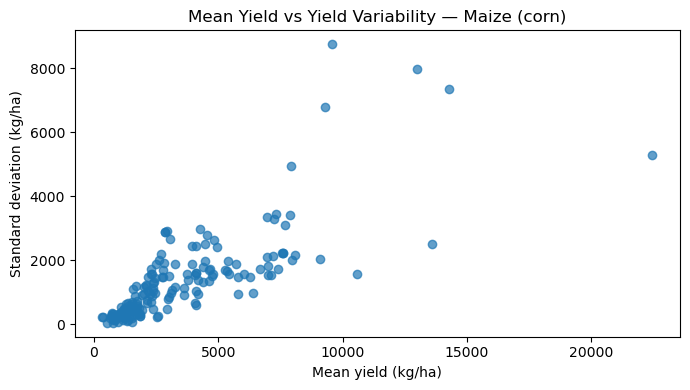

Maize (corn) correlation: 0.776


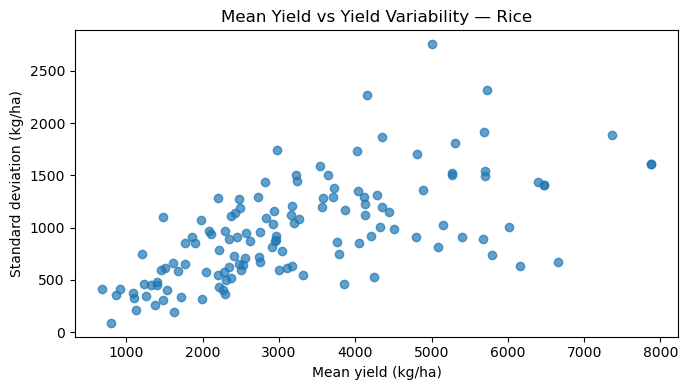

Rice correlation: 0.636


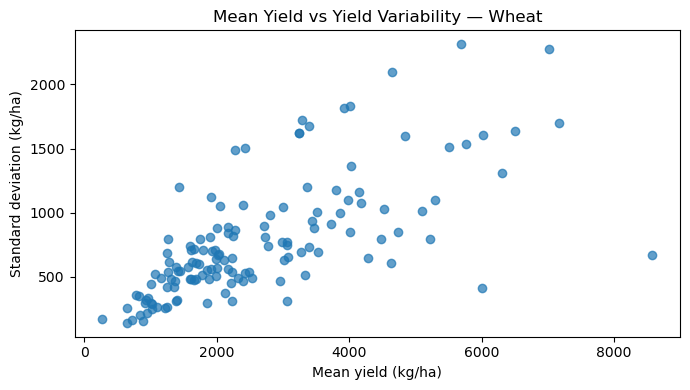

Wheat correlation: 0.681


In [19]:
## Q18 — comparing average yield and variability by area
area_variability = country_crop_data.groupby(["Area", "Item"])["Yield_kg_ha"].agg(
    observations="count", mean_yield="mean", yield_std="std"
).reset_index()
for crop in crop_order:
    g = area_variability[(area_variability["Item"] == crop) & (area_variability["observations"] >= 10)]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(g["mean_yield"], g["yield_std"], alpha=0.7)
    ax.set_title(f"Mean Yield vs Yield Variability — {crop}")
    ax.set_xlabel("Mean yield (kg/ha)")
    ax.set_ylabel("Standard deviation (kg/ha)")
    plt.tight_layout()
    plt.show()
    print(crop, "correlation:", round(g["mean_yield"].corr(g["yield_std"]), 3) if len(g) > 1 else "not enough areas")

 ## Q19 — finding largest differences from the previous year

In [20]:
## Q19 — finding largest differences from the previous year
display(changes.nlargest(15, "absolute_change")[
    ["Area", "Item", "Year", "Yield_lag_1", "Yield_kg_ha", "absolute_change"]
].round(2).reset_index(drop=True))
print("Review large changes against the original source; do not automatically remove them.")

,Area,Item,Year,Yield_lag_1,Yield_kg_ha,absolute_change
0,Oman,Maize (corn),2023,39405.7,5052.0,34353.7
1,United Arab Emirates,Maize (corn),2013,12112.2,36761.9,24649.7
2,United Arab Emirates,Maize (corn),2014,36761.9,14238.4,22523.5
3,Kuwait,Maize (corn),2015,30753.2,8467.6,22285.6
4,Oman,Maize (corn),2021,8597.4,30691.0,22093.6
5,United Arab Emirates,Maize (corn),2015,14238.4,35291.3,21052.9
6,Saint Vincent and the Grenadines,Maize (corn),2021,29241.4,14472.7,14768.7
7,Israel,Maize (corn),2015,34097.7,20695.3,13402.4
8,Saint Vincent and the Grenadines,Maize (corn),2000,3000.0,15000.0,12000.0
9,United Arab Emirates,Maize (corn),2012,24064.3,12112.2,11952.1


Review large changes against the original source; do not automatically remove them.


 ## Q20 — comparing lag relationships across crops

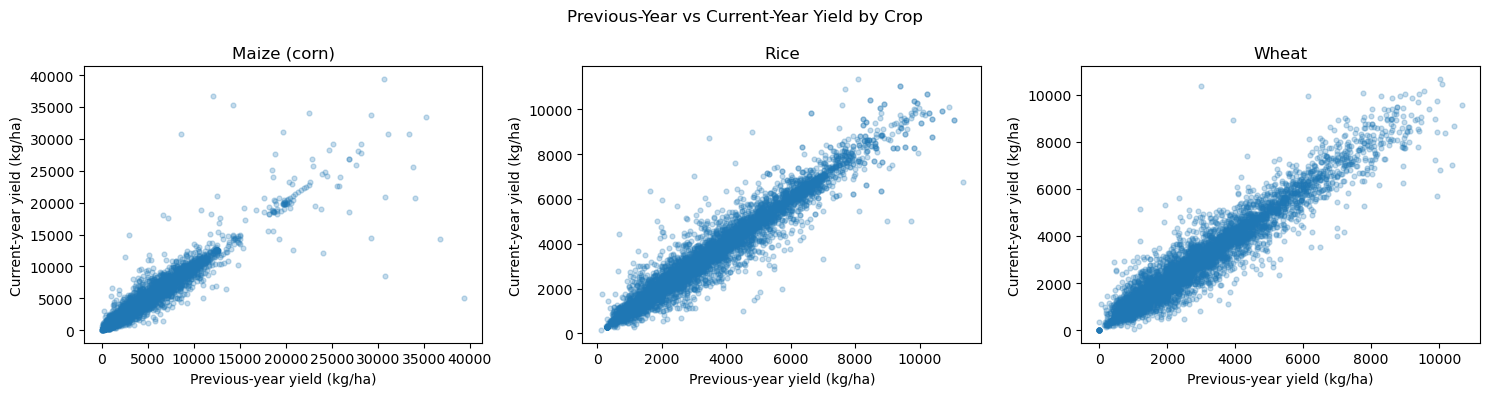

,observations,lag1_correlation
Item,,
Maize (corn),9635.0,0.953
Rice,7349.0,0.967
Wheat,7136.0,0.961


Compare both the correlation values and scatter patterns; extreme points can influence correlation.


In [21]:
## Q20 — comparing lag relationships across crops
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, crop in zip(axes, crop_order):
    g = lagged[lagged["Item"] == crop]
    ax.scatter(g["Yield_lag_1"], g["Yield_kg_ha"], alpha=0.25, s=12)
    ax.set_title(crop)
    ax.set_xlabel("Previous-year yield (kg/ha)")
    ax.set_ylabel("Current-year yield (kg/ha)")
plt.suptitle("Previous-Year vs Current-Year Yield by Crop")
plt.tight_layout()
plt.show()
correlations = lagged.groupby("Item").apply(
    lambda g: pd.Series({
        "observations": len(g),
        "lag1_correlation": g["Yield_lag_1"].corr(g["Yield_kg_ha"])
    }),
    include_groups=False
)
display(correlations.reindex(crop_order).round(3))
print("Compare both the correlation values and scatter patterns; extreme points can influence correlation.")

 ## saving the crop-wise EDA summary for later project use

In [23]:
## saving the crop-wise EDA summary for later project use
summary = country_crop_data.groupby("Item")["Yield_kg_ha"].agg(
    observations="count",
    median_yield="median",
    mean_yield="mean",
    minimum_yield="min",
    maximum_yield="max"
).round(3)
summary.to_csv(FILE_DIR / "eda_crop_summary.csv")
print("Saved EDA summary to:", FILE_DIR / "eda_crop_summary.csv")
print("EDA practice complete. Next: run 03_Feature_Selection_and_Model_Selection.ipynb")

Saved EDA summary to: C:\Users\acer\capstone_Project\Agriculture_Yield_Prediction\Crop_Field_Prediction_Using_ML\Data_Collection\eda_crop_summary.csv
EDA practice complete. Next: run 03_Feature_Selection_and_Model_Selection.ipynb
